# CNN(ResNet-18)

In [ ]:
import torchvision
import torchvision.transforms as transforms

# 預處理
transform = transforms.Compose([
    transforms.Resize(224),  # CLIP 預設 224x224
    transforms.ToTensor()
])

# 載入資料集
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)


100%|██████████| 170M/170M [00:13<00:00, 12.7MB/s]


Epoch [1/10]: 100%|██████████| 782/782 [02:01<00:00,  6.43it/s, loss=1.04]


[Epoch 1] Train Loss: 1.3174 | Train Acc: 0.5213 | Test Loss: 1.1035 | Test Acc: 0.6077


Epoch [2/10]: 100%|██████████| 782/782 [02:01<00:00,  6.45it/s, loss=0.852]


[Epoch 2] Train Loss: 0.8188 | Train Acc: 0.7115 | Test Loss: 0.7836 | Test Acc: 0.7289


Epoch [3/10]: 100%|██████████| 782/782 [02:01<00:00,  6.44it/s, loss=1.03]


[Epoch 3] Train Loss: 0.6199 | Train Acc: 0.7842 | Test Loss: 0.6249 | Test Acc: 0.7864


... (10 outputs left out)

Epoch [9/10]: 100%|██████████| 782/782 [02:01<00:00,  6.43it/s, loss=0.747]


[Epoch 9] Train Loss: 0.1295 | Train Acc: 0.9546 | Test Loss: 0.6059 | Test Acc: 0.8317


Epoch [10/10]: 100%|██████████| 782/782 [02:01<00:00,  6.43it/s, loss=0.0437]


[Epoch 10] Train Loss: 0.0959 | Train Acc: 0.9661 | Test Loss: 0.5667 | Test Acc: 0.8515


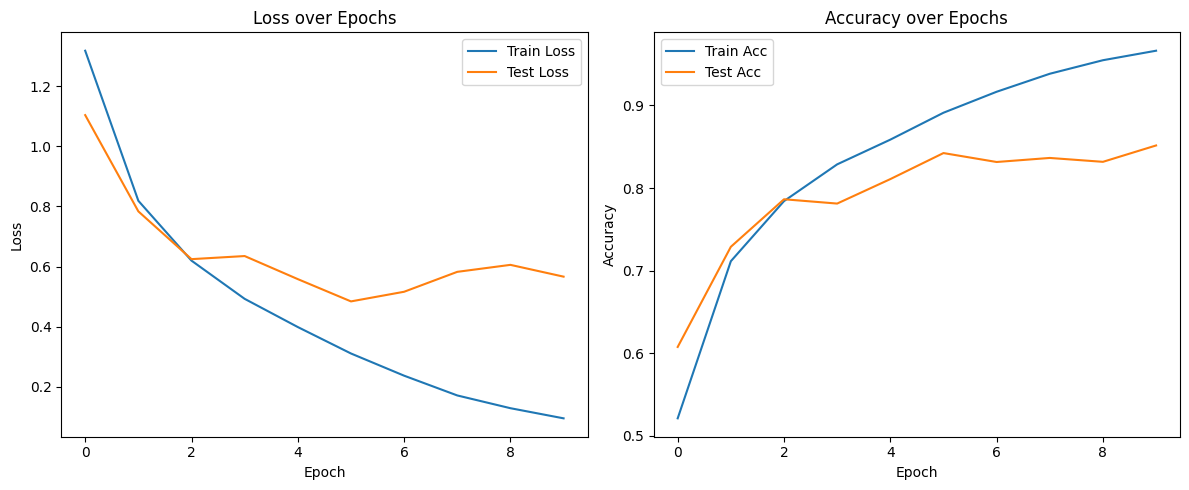

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet18
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt

# === 設定 ===
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = resnet18(num_classes=10).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
trainloader = DataLoader(trainset, batch_size=64, shuffle=True)
testloader = DataLoader(testset, batch_size=64)
num_epochs = 10

# === 儲存數據 ===
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

# === 訓練迴圈 ===
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_train, total_train = 0, 0
    loop = tqdm(trainloader, desc=f"Epoch [{epoch+1}/{num_epochs}]")

    for inputs, labels in loop:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predicted = outputs.argmax(1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

        loop.set_postfix(loss=loss.item())

    avg_train_loss = running_loss / len(trainloader)
    train_acc = correct_train / total_train
    train_losses.append(avg_train_loss)
    train_accuracies.append(train_acc)

    # === 驗證 ===
    model.eval()
    correct_test, total_test = 0, 0
    test_loss = 0.0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item()
            predicted = outputs.argmax(1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()

    avg_test_loss = test_loss / len(testloader)
    test_acc = correct_test / total_test
    test_losses.append(avg_test_loss)
    test_accuracies.append(test_acc)

    # === 印出每個 epoch 的結果 ===
    print(f"[Epoch {epoch+1}] Train Loss: {avg_train_loss:.4f} | Train Acc: {train_acc:.4f} | Test Loss: {avg_test_loss:.4f} | Test Acc: {test_acc:.4f}")

# ==== 畫圖 ====
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")
plt.title("Loss over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Train Acc")
plt.plot(test_accuracies, label="Test Acc")
plt.title("Accuracy over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


✅ Final Test Accuracy: 0.8515

=== Classification Report ===
              precision    recall  f1-score   support

    airplane       0.88      0.86      0.87      1000
  automobile       0.95      0.90      0.92      1000
        bird       0.79      0.78      0.79      1000
         cat       0.67      0.78      0.72      1000
        deer       0.83      0.81      0.82      1000
         dog       0.85      0.77      0.80      1000
        frog       0.87      0.88      0.87      1000
       horse       0.88      0.89      0.89      1000
        ship       0.93      0.92      0.92      1000
       truck       0.89      0.93      0.91      1000

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.85      0.85      0.85     10000



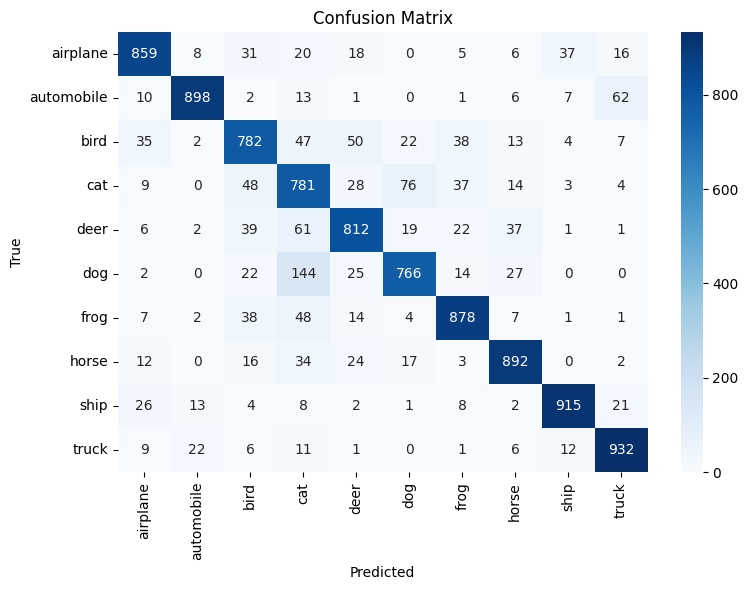

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# === 定義類別名稱（對應 CIFAR-10） ===
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# === 預測整個測試集 ===
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        predicted = outputs.argmax(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# === 計算準確率與報告 ===
acc = accuracy_score(all_labels, all_preds)
print(f"\n✅ Final Test Accuracy: {acc:.4f}\n")

# === 詳細 classification report ===
print("=== Classification Report ===")
print(classification_report(all_labels, all_preds, target_names=class_names))

# === 混淆矩陣 ===
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


# CLIP

In [ ]:
pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-_dqakio5
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-_dqakio5
  Resolved https://github.com/openai/CLIP.git to commit dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 126.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 98.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 60.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import clip
from PIL import Image
from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
model, preprocess = clip.load("ViT-B/32", device=device)

# 類別名稱
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
# 使用自然語言 prompt 生成 token
prompts = [f"a photo of a {label}" for label in class_names]
text_tokens = clip.tokenize(prompts).to(device)

# 評估
testset_clip = CIFAR10(root='./data', train=False, transform=preprocess)
testloader = DataLoader(testset_clip, batch_size=64)

correct, total = 0, 0
with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        logits_per_image, _ = model(images, text_tokens)
        predicted = logits_per_image.argmax(dim=1)
        total += labels.size(0)
        correct += (predicted == labels.to(device)).sum().item()

print(f"CLIP Zero-shot Accuracy: {correct / total:.4f}")


CLIP Zero-shot Accuracy: 0.8877


In [ ]:
from sklearn.metrics import classification_report

# 建立真實標籤與預測結果清單
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        logits_per_image, _ = model(images, text_tokens)
        predicted = logits_per_image.argmax(dim=1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

print("=== CLIP Zero-shot Classification Report ===")
print(classification_report(all_labels, all_preds, target_names=class_names))


=== CLIP Zero-shot Classification Report ===
              precision    recall  f1-score   support

    airplane       0.95      0.90      0.93      1000
  automobile       0.88      0.98      0.92      1000
        bird       0.81      0.89      0.85      1000
         cat       0.82      0.86      0.84      1000
        deer       0.93      0.77      0.84      1000
         dog       0.85      0.88      0.87      1000
        frog       0.97      0.77      0.86      1000
       horse       0.81      0.98      0.89      1000
        ship       0.95      0.95      0.95      1000
       truck       0.97      0.90      0.93      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



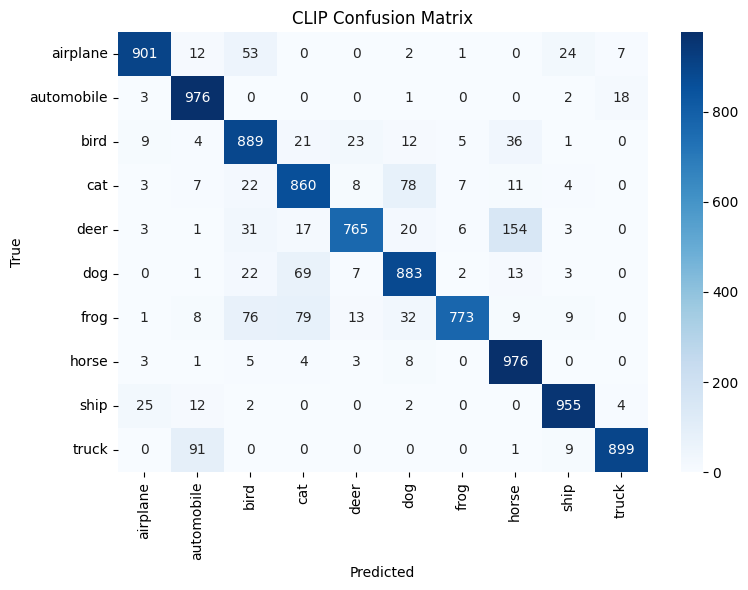

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("CLIP Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
topk_correct = 0
k = 3

with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        logits_per_image, _ = model(images, text_tokens)
        topk = logits_per_image.topk(k, dim=1).indices
        for i in range(labels.size(0)):
            if labels[i] in topk[i]:
                topk_correct += 1

topk_acc = topk_correct / total
print(f"CLIP Top-{k} Accuracy: {topk_acc:.4f}")


CLIP Top-3 Accuracy: 0.9775
